# CO5085 A1 · ResNet18 and Swin-T on CIFAR-100

Comparison of pretraining, fine-tuning depth, accuracy, and computational cost.

## 1. Configuration

In [1]:
import os
from pathlib import Path
import subprocess
import sys

candidates = [Path.cwd(), *Path.cwd().parents]
root = next((p for p in candidates if (p / "src/A1/protocol.py").is_file()), None)
if root is None:
    if "google.colab" not in sys.modules:
        raise FileNotFoundError(
            "Open the notebook from the CO5085-deep-learning repository."
        )
    root = Path("/content/CO5085-deep-learning")
    if not (root / "src/A1/protocol.py").is_file():
        subprocess.run(
            [
                "git",
                "clone",
                "https://github.com/dathuynh1108/CO5085-deep-learning.git",
                str(root),
            ],
            check=True,
        )
sys.path.insert(0, str(root / "src"))
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")


'4'

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display
from torchvision.datasets import CIFAR100
from torchvision.datasets.utils import download_url
from A1.data import development_data, loader
from A1.engine import epoch_pass, test_run, train_run
from A1.models import build_model
from A1.protocol import load_protocol
from common.runtime import atomic_json, choose_device


### Fixed protocols

Eight configurations run for 20 epochs; two Swin-T initializations share a 40-epoch follow-up schedule. Both use seeds 42, 43, and 44.

In [3]:
settings = {
    "assignment1": root / "configs/a1_experiments.json",
    "a1_swin_followup": root / "configs/a1_swin_followup.json",
}
protocol_names = os.getenv("CO5085_A1_PROTOCOLS", ",".join(settings)).split(",")
seeds = [int(seed) for seed in os.getenv("CO5085_A1_SEEDS", "42,43,44").split(",")]
output_root = Path(
    os.getenv("CO5085_A1_OUTPUT_ROOT", str(root / "runs/notebooks"))
).resolve()
data_root = Path(os.getenv("CO5085_A1_DATA_ROOT", str(root / "data"))).resolve()
workers = int(os.getenv("CO5085_A1_WORKERS", "8"))
resume = os.getenv("CO5085_A1_RESUME", "0") == "1"
confirm_test = os.getenv("CO5085_A1_CONFIRM_TEST", "0") == "1"


In [4]:
device = choose_device(os.getenv("CO5085_A1_DEVICE", "cuda"))
if device.type == "cuda" and not torch.cuda.is_bf16_supported(
    including_emulation=False
):
    raise RuntimeError("The A1 protocol requires a GPU with native BF16 support.")
if len(set(seeds)) != len(seeds) or any(seed < 0 for seed in seeds) or workers < 0:
    raise ValueError(
        "Seeds must be distinct and nonnegative, and the worker count must be nonnegative."
    )
protocols = {name: load_protocol(settings[name]) for name in protocol_names}
output_root.mkdir(parents=True, exist_ok=True)
print(f"Device: {device} · seeds: {seeds} · output directory: {output_root}")
for name, protocol in protocols.items():
    print(
        name,
        protocol["epochs"],
        "epochs",
        len(protocol["experiments"]),
        "configurations",
    )


Device: cuda · seeds: [42, 43, 44] · output directory: /workspace/co5085/runs/notebooks
assignment1 20 epochs 8 configurations
a1_swin_followup 40 epochs 2 configurations


## 2. Data exploration

Full CIFAR-100: 100 classes and 45,000/5,000/10,000 training/validation/test images. Training uses random crops and flips; all images are resized from 32 × 32 to 96 × 96.

In [5]:
if not (data_root / CIFAR100.base_folder / "meta").is_file():
    # This mirror preserves the original Toronto archive checksum.
    mirror = (
        "https://zenodo.org/records/10089977/files/cifar-100-python.tar.gz?download=1"
    )
    download_url(
        mirror, str(data_root), filename=CIFAR100.filename, md5=CIFAR100.tgz_md5
    )
    CIFAR100(str(data_root), train=True, download=True)

first = protocols[protocol_names[0]]
train_data, val_data, split, data_identity = development_data(data_root, first)
pixels = train_data.dataset.data
labels = np.asarray(train_data.dataset.targets)
train_counts = np.bincount(labels[split["train"]], minlength=100)
val_counts = np.bincount(labels[split["val"]], minlength=100)
assert len(train_data) == 45_000 and len(val_data) == 5_000
print(f"{len(train_data):,} training images and {len(val_data):,} validation images")
print(
    "Training-set RGB mean:", np.round(pixels[split["train"]].mean((0, 1, 2)) / 255, 4)
)


0.0%

0.0%

0.1%

0.1%

0.1%

0.1%

... (5,149 outputs left out)

100.0%

100.0%

100.0%

45,000 training images and 5,000 validation images
Training-set RGB mean: [0.5074 0.4868 0.4412]


### Class balance

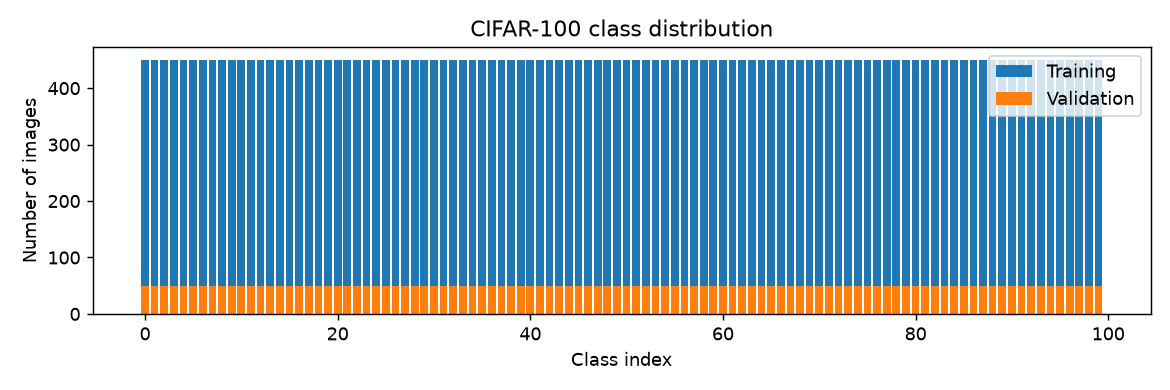

In [6]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(np.arange(100), train_counts, label="Training")
ax.bar(np.arange(100), val_counts, label="Validation")
ax.set(
    xlabel="Class index",
    ylabel="Number of images",
    title="CIFAR-100 class distribution",
)
ax.legend()
fig.tight_layout()
fig.savefig(output_root / "a1-class-counts.png", dpi=130)
display(Image(filename=str(output_root / "a1-class-counts.png")))
plt.close(fig)


### Original images

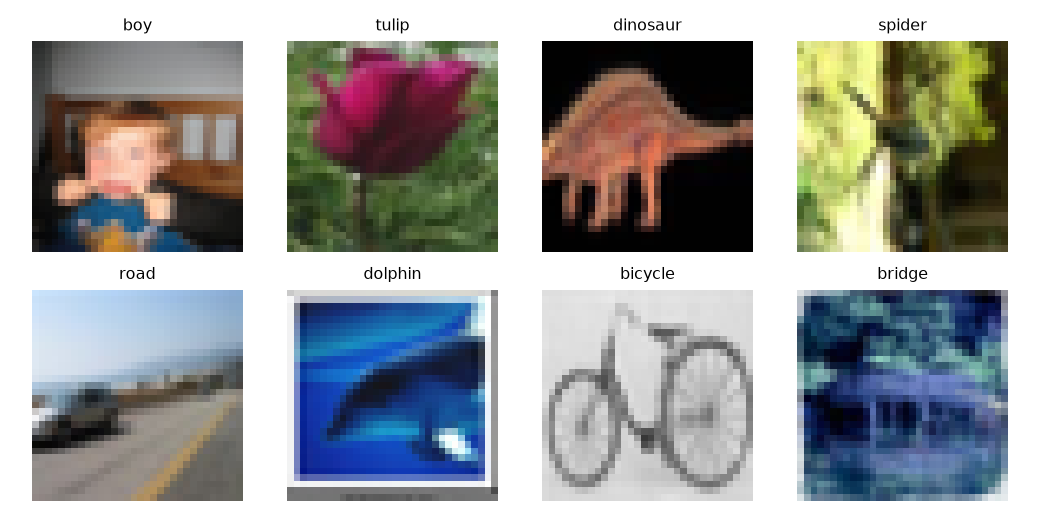

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(8, 4))
examples = np.random.default_rng(seeds[0]).choice(
    split["train"], len(axes.flat), replace=False
)
for ax, index in zip(axes.flat, examples):
    ax.imshow(pixels[index])
    ax.set_title(split["classes"][labels[index]], fontsize=9)
    ax.axis("off")
fig.tight_layout()
fig.savefig(output_root / "a1-samples.png", dpi=130)
display(Image(filename=str(output_root / "a1-samples.png")))
plt.close(fig)


## 3. Training

Validation accuracy selects checkpoints; cross-entropy breaks ties.

In [8]:
jobs = []
for name, protocol in protocols.items():
    for experiment in protocol["experiments"]:
        for seed in seeds:
            run = output_root / name / experiment["id"] / f"seed_{seed}"
            options = dict(
                run=run,
                protocol=protocol,
                experiment=experiment,
                seed=seed,
                data_root=data_root,
                device=device,
                workers=workers,
                config=settings[name],
            )
            print(f"{name} · {experiment['id']} · seed {seed}", flush=True)
            metadata = train_run(**options, resume=resume)
            assert metadata["status"] == "trained"
            jobs.append((name, options))


assignment1 · resnet18_scratch · seed 42


resnet18_scratch seed=42 epoch=1/20 val_acc=0.1892


resnet18_scratch seed=42 epoch=2/20 val_acc=0.2966


resnet18_scratch seed=42 epoch=3/20 val_acc=0.3570


resnet18_scratch seed=42 epoch=4/20 val_acc=0.3902


resnet18_scratch seed=42 epoch=5/20 val_acc=0.4340


... (1,966 outputs left out)

swin_t_full seed=44 epoch=37/40 val_acc=0.8614


swin_t_full seed=44 epoch=38/40 val_acc=0.8604


swin_t_full seed=44 epoch=39/40 val_acc=0.8596


swin_t_full seed=44 epoch=40/40 val_acc=0.8608


## 4. Evaluation

In [9]:
rows, matrices = [], {}
for name, options in jobs:
    run = options["run"]
    preset, seed = options["experiment"], options["seed"]
    record = json.loads((run / "metadata.json").read_text())
    if confirm_test:
        metrics = test_run(**options)
    else:
        model = build_model(preset, initialize_pretrained=False).to(device)
        checkpoint = torch.load(run / "best.pt", map_location="cpu", weights_only=False)
        model.load_state_dict(checkpoint["model"])
        batches = loader(
            val_data,
            options["protocol"]["batch_size"],
            workers,
            torch.Generator().manual_seed(seed + 1),
            False,
            device,
        )
        metrics = epoch_pass(model, batches, device)
        del model, checkpoint, batches
    label = (name, preset["id"])
    matrices[label] = matrices.get(label, 0) + np.asarray(metrics["confusion"])
    rows.append(
        {
            "Protocol": name,
            "Configuration": preset["id"],
            "Seed": seed,
            "Split": "Test" if confirm_test else "Validation",
            "Selected epoch": record["best_validation"]["epoch"],
            "Accuracy": metrics["accuracy"],
            "Macro-F1": metrics["macro_f1"],
            "Trainable parameters": record["trainable_params"],
            "Training time (s)": record["train_seconds"],
            "VRAM MiB": record["peak_gpu_memory_bytes"] / 2**20,
        }
    )


### Metrics across seeds

In [10]:
results = pd.DataFrame(rows)
display(results.round(4))
display(
    results.groupby(["Protocol", "Configuration"])[["Accuracy", "Macro-F1"]]
    .agg(["mean", "std"])
    .round(4)
)
results.to_csv(
    output_root / f'a1-metrics-seeds-{"-".join(map(str, seeds))}.csv', index=False
)
atomic_json(
    output_root / f'a1-config-seeds-{"-".join(map(str, seeds))}.json',
    {
        "seeds": seeds,
        "protocols": protocols,
        "data": data_identity,
        "test": confirm_test,
        "runs": [str(options["run"]) for _, options in jobs],
    },
)


,Protocol,Configuration,Seed,Split,Selected epoch,Accuracy,Macro-F1,Trainable parameters,Training time (s),VRAM MiB
0,assignment1,resnet18_scratch,42,Test,20,0.6425,0.6413,11227812,90.5907,522.6104
1,assignment1,resnet18_scratch,43,Test,19,0.6434,0.6418,11227812,80.4420,518.8604
2,assignment1,resnet18_scratch,44,Test,20,0.6446,0.6435,11227812,88.7463,518.8604
3,assignment1,resnet18_head,42,Test,20,0.6119,0.6105,51300,80.1653,251.0137
4,assignment1,resnet18_head,43,Test,18,0.6063,0.6047,51300,80.2014,251.0137
5,assignment1,resnet18_head,44,Test,20,0.6103,0.6090,51300,79.8261,251.0137
6,assignment1,resnet18_partial,42,Test,19,0.7383,0.7384,8445028,79.9712,347.3223
7,assignment1,resnet18_partial,43,Test,17,0.7405,0.7404,8445028,80.2737,347.3223
8,assignment1,resnet18_partial,44,Test,20,0.7401,0.7400,8445028,80.4605,347.3223
9,assignment1,resnet18_full,42,Test,19,0.7899,0.7904,11227812,79.8552,518.8604


Accuracy         Macro-F1        
                                      mean     std     mean     std
Protocol         Configuration                                     
a1_swin_followup swin_t_full        0.8639  0.0034   0.8637  0.0034
                 swin_t_scratch     0.6030  0.0005   0.6021  0.0006
assignment1      resnet18_full      0.7897  0.0004   0.7898  0.0006
                 resnet18_head      0.6095  0.0029   0.6081  0.0030
                 resnet18_partial   0.7396  0.0012   0.7396  0.0011
                 resnet18_scratch   0.6435  0.0011   0.6422  0.0012
                 swin_t_full        0.8663  0.0022   0.8663  0.0020
                 swin_t_head        0.7167  0.0009   0.7154  0.0009
                 swin_t_partial     0.7825  0.0022   0.7818  0.0021
                 swin_t_scratch     0.0276  0.0126   0.0093  0.0069

## 5. Learning curves

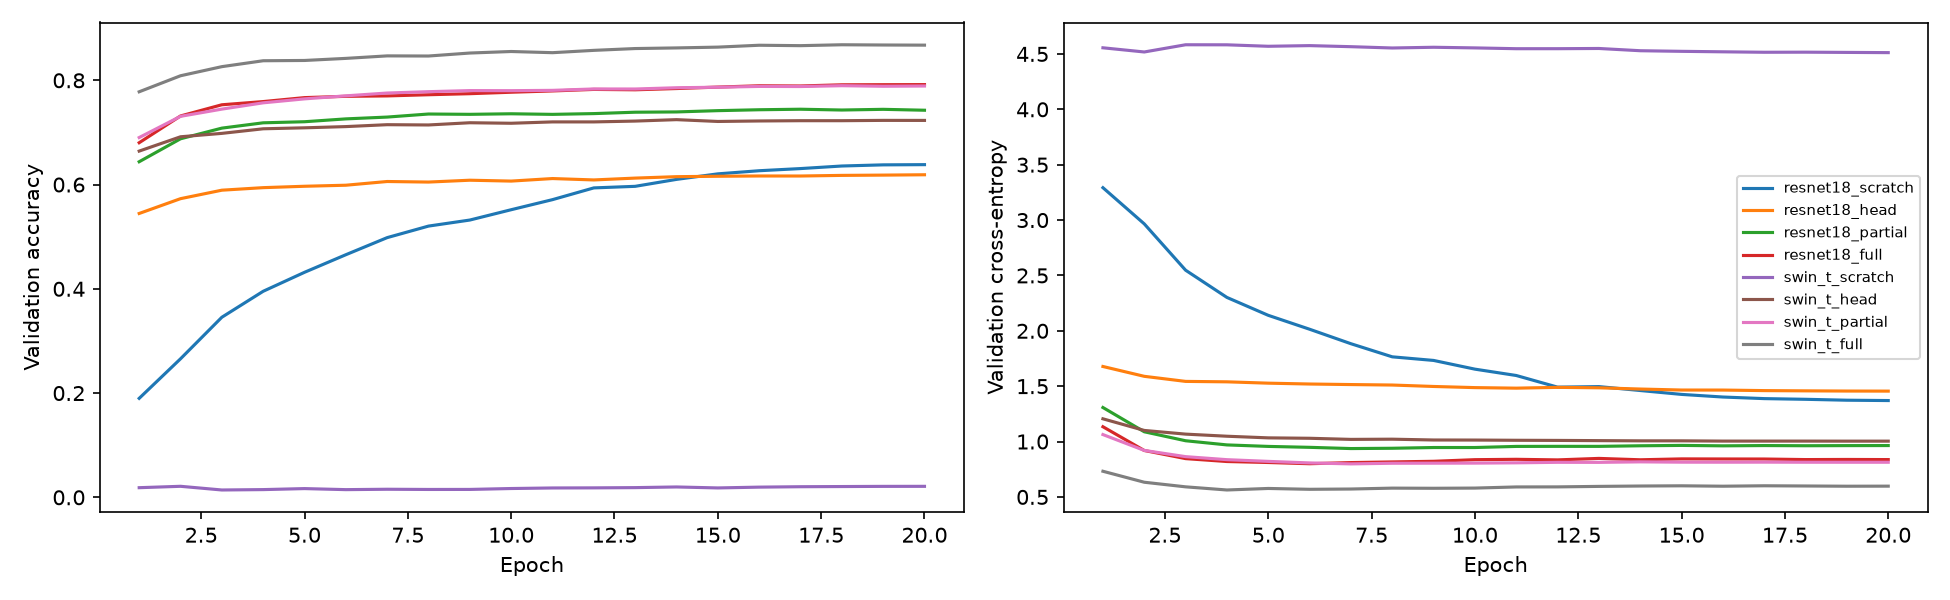

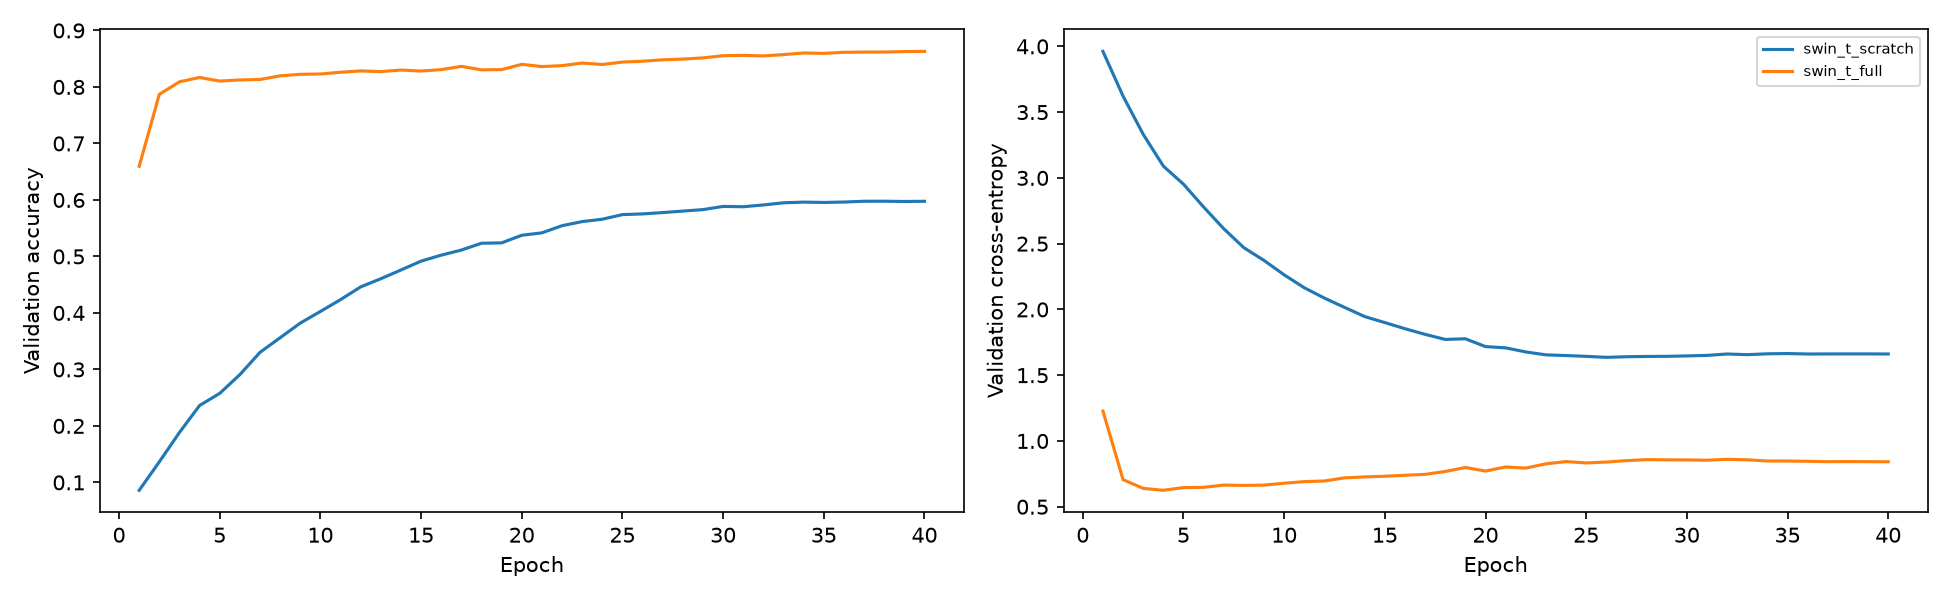

In [11]:
for name, protocol in protocols.items():
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for preset in protocol["experiments"]:
        histories = []
        for seed in seeds:
            history = output_root / name / preset["id"] / f"seed_{seed}" / "history.csv"
            histories.append(pd.read_csv(history))
        for ax, metric, title in zip(
            axes,
            ["val_accuracy", "val_ce"],
            ["Validation accuracy", "Validation cross-entropy"],
        ):
            values = np.stack([history[metric] for history in histories])
            ax.plot(histories[0]["epoch"], values.mean(0), label=preset["id"])
            ax.set(xlabel="Epoch", ylabel=title)
    axes[1].legend(fontsize=7)
    fig.tight_layout()
    path = output_root / f'{name}-curves-{"-".join(map(str, seeds))}.png'
    fig.savefig(path, dpi=150)
    display(Image(filename=str(path)))
    plt.close(fig)


### Confusion matrices

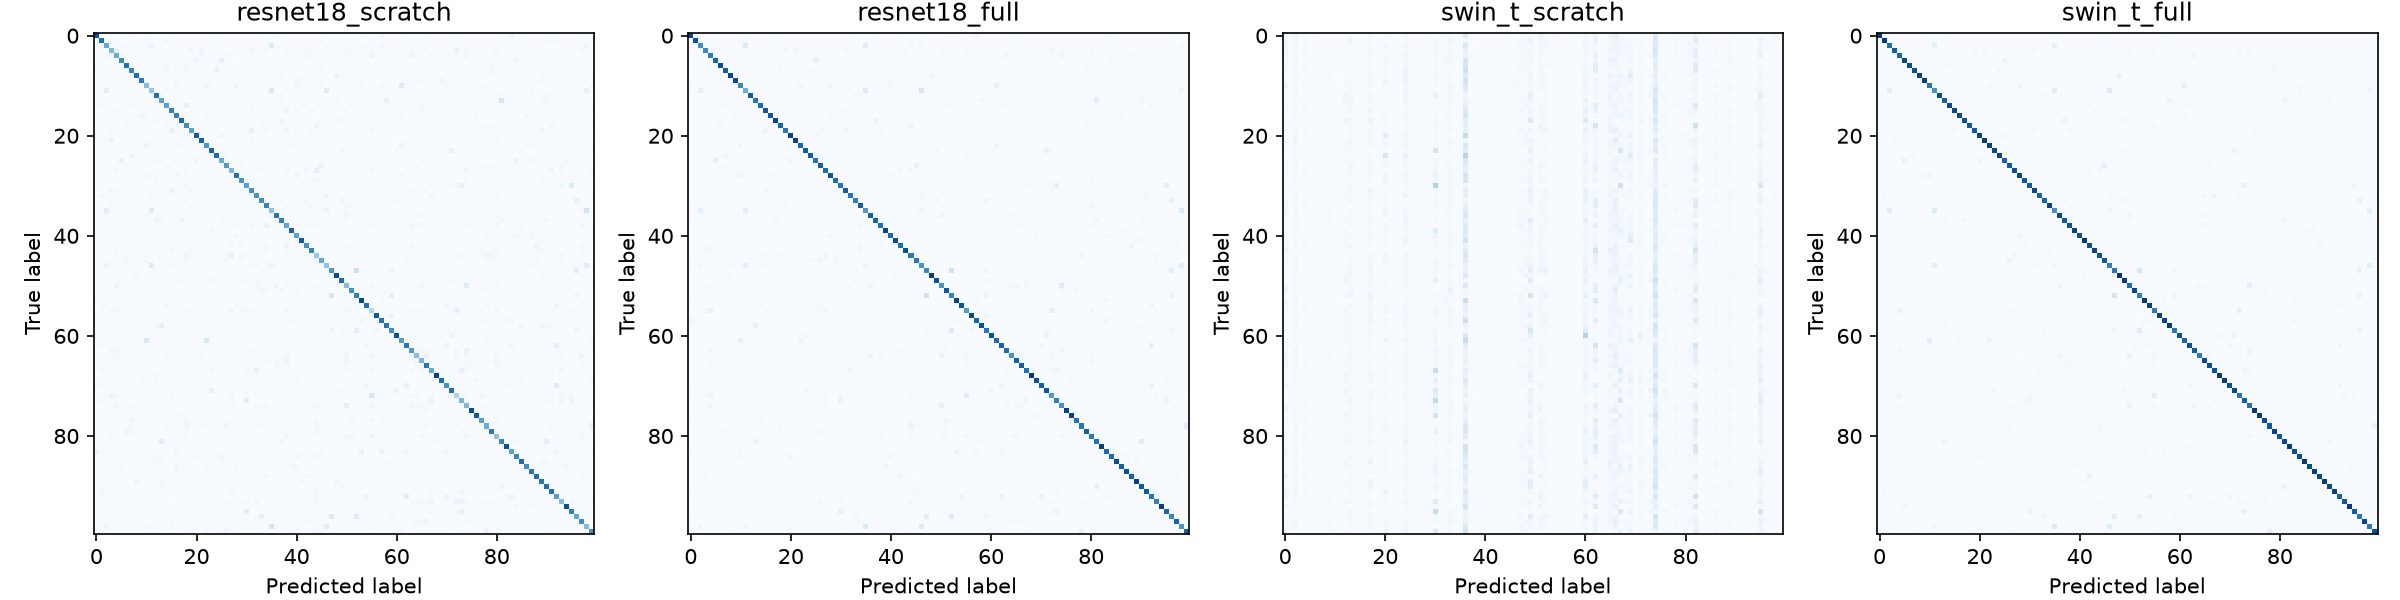

,Configuration,True label,Predicted label,Error count
0,resnet18_scratch,maple_tree,oak_tree,61
1,resnet18_full,oak_tree,maple_tree,61
2,swin_t_scratch,cockroach,hamster,89
3,swin_t_full,oak_tree,maple_tree,54


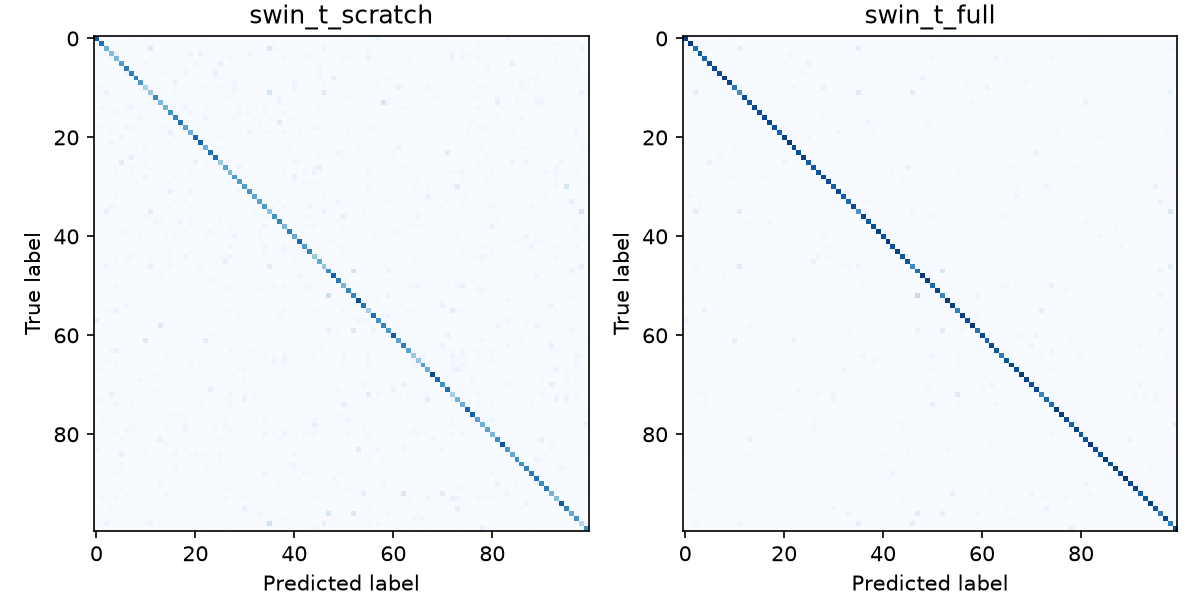

,Configuration,True label,Predicted label,Error count
0,swin_t_scratch,oak_tree,maple_tree,64
1,swin_t_full,oak_tree,maple_tree,73


In [12]:
for name, protocol in protocols.items():
    ids = [
        preset["id"]
        for preset in protocol["experiments"]
        if preset["regime"] in ("scratch", "full")
    ]
    fig, axes = plt.subplots(1, len(ids), figsize=(4 * len(ids), 4), squeeze=False)
    mistakes = []
    for ax, preset_id in zip(axes.flat, ids):
        matrix = matrices[name, preset_id]
        proportions = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1)
        ax.imshow(proportions, cmap="Blues", vmin=0, vmax=1)
        ax.set(title=preset_id, xlabel="Predicted label", ylabel="True label")
        off_diagonal = matrix.copy()
        np.fill_diagonal(off_diagonal, 0)
        actual, predicted = np.unravel_index(off_diagonal.argmax(), matrix.shape)
        mistakes.append(
            (
                preset_id,
                split["classes"][actual],
                split["classes"][predicted],
                int(off_diagonal[actual, predicted]),
            )
        )
    fig.tight_layout()
    path = output_root / f'{name}-confusion-{"-".join(map(str, seeds))}.png'
    fig.savefig(path, dpi=150)
    display(Image(filename=str(path)))
    plt.close(fig)
    display(
        pd.DataFrame(
            mistakes,
            columns=["Configuration", "True label", "Predicted label", "Error count"],
        )
    )


## 6. Scope and limitations

The 40-epoch comparison holds optimization settings constant between initializations. Changes across schedules and identical images across splits limit broader conclusions.